# Previsão de demanda por turno — Fila Zero UBS

Modelo de regressão que prevê quantas pessoas vão procurar a UBS em cada turno do dia seguinte.

- **Dados:** sintéticos, gerados por `data/gerar_dataset.py` e lidos da camada gold do lake (`bigdata/pipeline.py`).
- **Variáveis:** UBS, turno, dia da semana, mês, dia útil após feriado, temperatura máxima, chuva do dia, chuva dos 7 dias anteriores e média móvel da procura nos 7 dias de funcionamento anteriores.
- **Teste:** os últimos 30 dias do histórico. Nenhum modelo vê esses dias antes da medição.
- **Meta:** MAE abaixo de 15% da procura média do turno.

O código de treino fica em `ia/treinar.py` e o de uso em `ia/previsao.py`; este notebook roda os dois e mostra o resultado.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / "ia").is_dir() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import pandas as pd

from ia.previsao import VARIAVEIS, Previsor, montar_base
from ia.treinar import GOLD, carregar_gold, treinar

## 1. Dados de treino (camada gold)

In [2]:
demanda, dim_data, lista_ubs, feriados = carregar_gold()
base = montar_base(demanda, dim_data, lista_ubs)
print(f"{len(base)} linhas (uma por data, UBS e turno), de {base['data'].min()} a {base['data'].max()}")
base[["data", "ubs", "turno", "procura", *VARIAVEIS]].tail(6)

1488 linhas (uma por data, UBS e turno), de 2025-11-04 a 2026-10-30


,data,ubs,turno,procura,ubs_cod,turno_cod,dia_semana,mes,pos_feriado,temp_max,chuva_mm,chuva_7d_mm,media_movel_7d
1482,2026-10-23,UBS Vila Nova,tarde,36,1,1,4,10,0,26.2,0.0,70.9,35.571429
1483,2026-10-26,UBS Vila Nova,tarde,39,1,1,0,10,0,25.5,0.0,113.2,36.000000
1484,2026-10-27,UBS Vila Nova,tarde,30,1,1,1,10,0,25.5,0.0,102.6,38.000000
1485,2026-10-28,UBS Vila Nova,tarde,27,1,1,2,10,0,27.0,10.9,75.7,39.000000
1486,2026-10-29,UBS Vila Nova,tarde,31,1,1,3,10,0,28.6,13.2,86.6,35.571429
1487,2026-10-30,UBS Vila Nova,tarde,35,1,1,4,10,0,23.5,0.0,66.4,33.857143


## 2. Treino e escolha do modelo

Dois candidatos do scikit-learn: `RandomForestRegressor` e `GradientBoostingRegressor`. A escolha é feita nos 30 dias anteriores ao teste (validação), para o teste não participar da decisão.

In [3]:
metricas = treinar()
print("MAE na validação:", metricas["mae_validacao_por_candidato"])
print("Escolhido:", metricas["modelo"])
print("Treino:", metricas["periodo_treino"], "| Teste:", metricas["periodo_teste"])

MAE na validação: {'RandomForest': 5.69, 'GradientBoosting': 5.43}
Escolhido: GradientBoosting
Treino: ['2025-11-04', '2026-09-30'] | Teste: ['2026-10-01', '2026-10-30']


## 3. MAE no teste

A linha de base é prever a média móvel dos 7 dias anteriores, sem modelo nenhum.

In [4]:
tabela = pd.DataFrame(metricas["teste"]["por_turno"]).T
tabela["mae_linha_de_base"] = [v["mae"] for v in metricas["linha_de_base_media_movel_7d"]["por_turno"].values()]
tabela = tabela.rename(columns={"mae": "MAE", "media": "procura média", "pct_da_media": "MAE em % da média",
                                "meta_ok": "meta < 15%", "mae_linha_de_base": "MAE da linha de base"})
print(f"MAE geral: {metricas['teste']['mae_geral']} | linha de base: {metricas['linha_de_base_media_movel_7d']['mae_geral']}")
tabela

MAE geral: 5.38 | linha de base: 7.24


,MAE,procura média,MAE em % da média,meta < 15%,MAE da linha de base
manha,6.57,54.2,12.1,True,9.88
tarde,5.55,39.8,13.9,True,7.83
noite,4.01,17.1,23.5,False,3.99


## 4. Previsto × real no período de teste

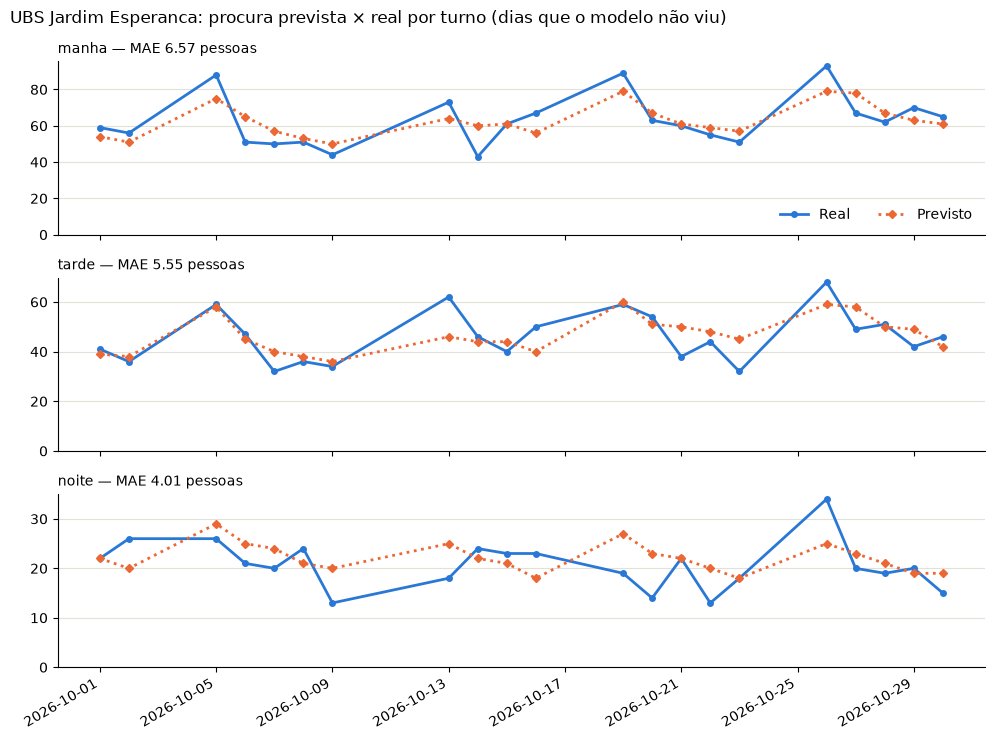

In [5]:
prev = pd.read_parquet(GOLD / "fato_previsao.parquet")
teste = prev[prev["conjunto"] == "teste"]
ubs = lista_ubs[0]
fig, eixos = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
for eixo, turno in zip(eixos, ["manha", "tarde", "noite"]):
    serie = teste[(teste["ubs"] == ubs) & (teste["turno"] == turno)]
    dias = pd.to_datetime(serie["data"])
    eixo.plot(dias, serie["real"], color="#2a78d6", marker="o", markersize=4, linewidth=2, label="Real")
    eixo.plot(dias, serie["previsto"], color="#eb6834", marker="D", markersize=4, linewidth=2, linestyle=":", label="Previsto")
    eixo.set_title(f"{turno} — MAE {metricas['teste']['por_turno'][turno]['mae']} pessoas", loc="left", fontsize=10)
    eixo.set_ylim(bottom=0)
    eixo.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    eixo.spines[["top", "right"]].set_visible(False)
eixos[0].legend(frameon=False, ncols=2, loc="lower right")
fig.suptitle(f"{ubs}: procura prevista × real por turno (dias que o modelo não viu)", x=0.01, ha="left", fontsize=12)
fig.autofmt_xdate()
fig.tight_layout()
(RAIZ / "docs").mkdir(exist_ok=True)
fig.savefig(RAIZ / "docs" / "previsto_x_real.png", dpi=150)
plt.show()

## 5. Usando o modelo salvo (o mesmo que a API carrega)

In [6]:
from datetime import date

previsor = Previsor.carregar()
for dia in (date(2026, 11, 23), date(2026, 11, 20)):
    print(dia, previsor.motivo_fechada(dia) or "aberta", previsor.prever(dia, ubs))

2026-11-23 aberta {'manha': 83, 'tarde': 59, 'noite': 24}
2026-11-20 feriado {'manha': 0, 'tarde': 0, 'noite': 0}


## Leitura do resultado

- Manhã e tarde ficam abaixo da meta de 15% e o modelo erra menos que a linha de base.
- A noite não bate a meta. Com cerca de 17 pessoas por turno, um erro de 3 a 4 pessoas já passa de 15%, e o modelo não ganha da média móvel. Nesse volume a variação de um dia para o outro é quase toda acaso.
- Os dados são sintéticos: o MAE mede se o modelo recupera a sazonalidade que o gerador embutiu, não o desempenho em uma UBS real.